## step1:load the dataset using pandas library

In [1]:
#import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_excel('pima-data.xlsx')
df

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True
...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,1.8912,False
764,2,122,70,27,0,36.8,0.340,27,0,1.0638,False
765,5,121,72,23,112,26.2,0.245,30,0,0.9062,False
766,1,126,60,0,0,30.1,0.349,47,1,0.0000,True


In [3]:
df.shape


(768, 11)

In [4]:
pd.set_option('display.max_rows',None)

In [5]:
df

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True
5,5,116,74,0,0,25.6,0.201,30,0,0.0000,False
6,3,78,50,32,88,31.0,0.248,26,1,1.2608,True
7,10,115,0,0,0,35.3,0.134,29,0,0.0000,False
8,2,197,70,45,543,30.5,0.158,53,1,1.7730,True
9,8,125,96,0,0,0.0,0.232,54,1,0.0000,True


In [6]:
df.columns

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'thickness', 'insulin',
       'bmi', 'diab_pred', 'age', 'diabetes_orig', 'skin', 'diabetes'],
      dtype='object')

## step 2: cleaning the data 

# a finding the null values

In [7]:
df.isnull().values.any()

np.False_

In [8]:
df.isnull().values.sum()

np.int64(0)

In [9]:
df.isnull()

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,diabetes
0,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False,False,False,False
9,False,False,False,False,False,False,False,False,False,False,False


## step3:remove duplicate code

# find the coreelation between columns

In [10]:
def plot_corr(df,size=12):
    corr=df.corr()
    fig,ax=plt.subplots(figsize=(size,size))
    cmap="plasma"
    ax.matshow(corr,cmap=cmap)
    plt.xticks(range(len(corr.columns)),corr.columns,rotation=20)
    plt.yticks(range(len(corr.columns)),corr.columns)
    plt.show()

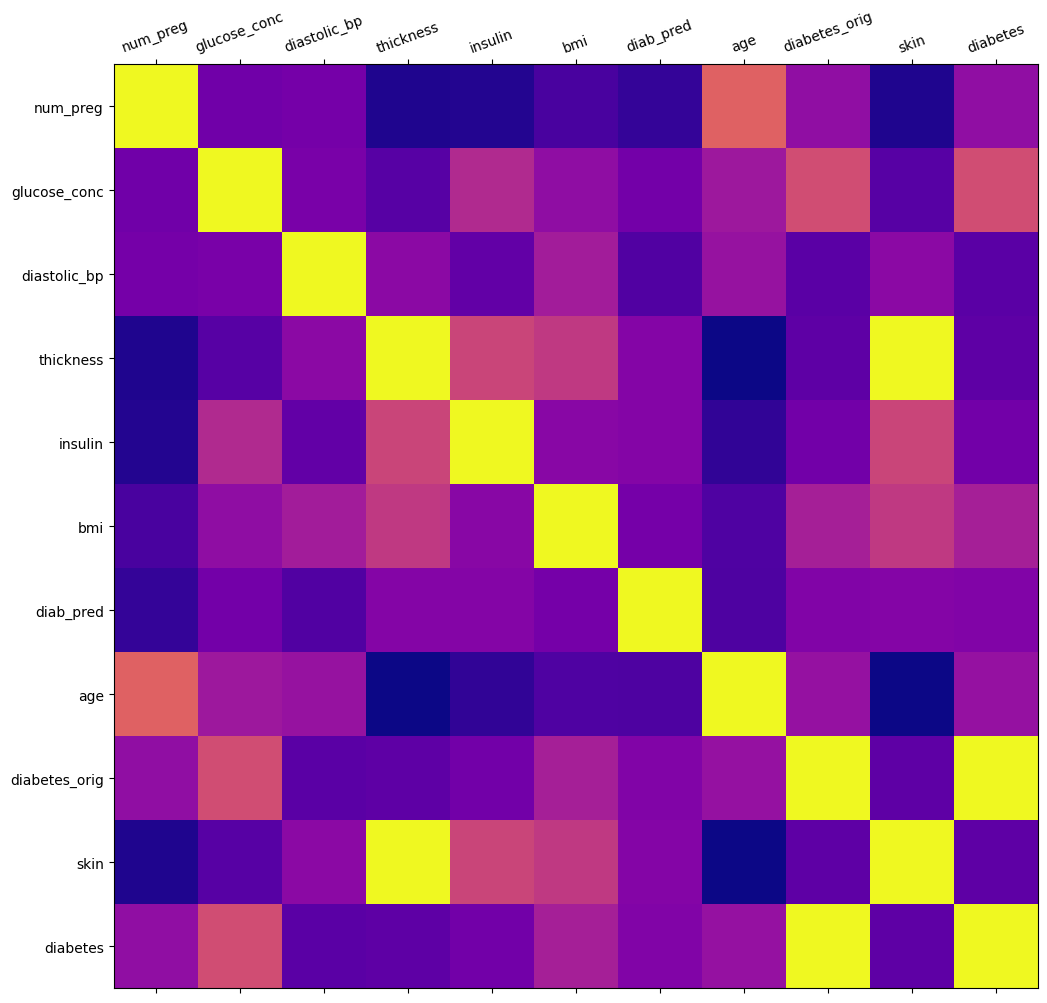

In [11]:
plot_corr(df)

In [12]:
## correlated columns
## thickness and skin are correlated to each other
## diabetes_origin and has_diabetes are correlated to each other
## diabetes_origin and diabetes are correlated to each other
## has_diabetes and diabetes are correlated to each other



In [13]:
# 3.drop the correlated columns
df.drop('thickness',axis=1,inplace=True)
#df.drop('diabetes',axis=1,inplace=True)
df.drop('diabetes_orig',axis=1,inplace=True) 

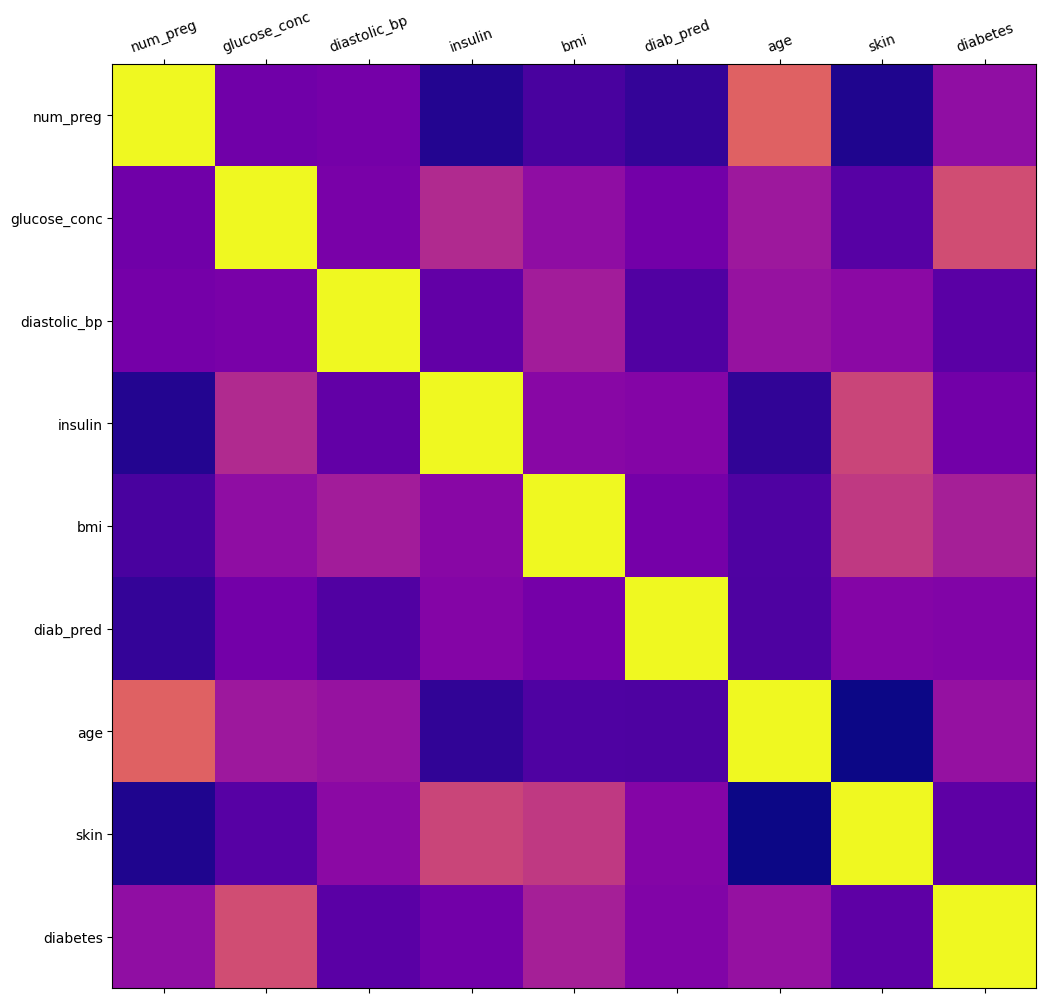

In [14]:
plot_corr(df)

In [15]:
print(df.columns.tolist())

['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi', 'diab_pred', 'age', 'skin', 'diabetes']


In [16]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,True
1,1,85,66,0,26.6,0.351,31,1.1426,False
2,8,183,64,0,23.3,0.672,32,0.0000,True
3,1,89,66,94,28.1,0.167,21,0.9062,False
4,0,137,40,168,43.1,2.288,33,1.3790,True


# convert text to integer

In [17]:
#creating a dictionary to convert True to 1 and false to 0
# want to replace True and FAlse in Diabetes columns
dict1={
    'diabetes':[True,False]
}
# inplace of true place with 1 and in place of false place with 0
dict2={
    'diabetes':[1,0]
}


In [18]:
df.replace(dict1,dict2,inplace=True)

C:\Users\sunee\AppData\Local\Temp\ipykernel_9568\3065561261.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace(dict1,dict2,inplace=True)


In [19]:
num_true = len(df.loc[df['diabetes']==1])
num_false = len(df.loc[df['diabetes'] == 0])

print(f'num_true = {num_true}')
print(f'num_false = {num_false}')

per_num_true = (num_true / (num_true+num_false))*100
print(per_num_true)

per_num_false = (num_false/(num_false+num_true))*100
print(per_num_false)

num_true = 268
num_false = 500
34.89583333333333
65.10416666666666


# train_test_Split

In [20]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: scikit-learn in c:\users\sunee\appdata\local\programs\python\python313\lib\site-packages (1.8.0)




[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
from sklearn.model_selection import train_test_split

input_columns = ['num_preg','glucose_conc','diastolic_bp','insulin','bmi','diab_pred','age','skin']
output_columns = ['diabetes']

x = df[input_columns].values
y = df[output_columns].values

spilt_test_size = 0.3

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = spilt_test_size,random_state=42)


In [22]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(537, 8)
(537, 1)
(231, 8)
(231, 1)


In [23]:
# check the training propertion and yesting proportion
print('{0:0.2f}% in training set'.format((len(x_train)/len(df.index))*100))
print('{0:0.2f}% in training set'.format((len(x_test)/len(df.index))*100))

69.92% in training set
30.08% in training set


In [24]:
print('training true:{0} ({1:0.2f}%)'.format(len(y_train[y_train[ : ] == 1]),len(y_train[y_train[ : ] == 1])/len(y_train) * 100))


print('training False:{0} ({1:0.2f}%)'.format(len(y_train[y_train[ : ] == 0]),len(y_train[y_train[ : ] == 0])/len(y_train) * 100))
print('Test true:{0} ({1:0.2f}%)'.format(len(y_test[y_test[ : ] == 1]),len(y_test[y_test[ : ] == 1])/len(y_train) * 100))
print('Test false:{0} ({1:0.2f}%)'.format(len(y_test[y_test[ : ] == 0]),len(y_test[y_test[ : ] == 0])/len(y_train) * 100))


training true:188 (35.01%)
training False:349 (64.99%)
Test true:80 (14.90%)
Test false:151 (28.12%)


# step4:post split data preparation

In [25]:
total_num_preg = len(df.loc[df['num_preg']== 0])
print(f'number of Rows missing in num_preg column is {total_num_preg}')

total_glucose_conc =  len(df.loc[df['glucose_conc']==0])
print(f'number of Rows missing in glucose_conc column is {total_glucose_conc}')

total_diastolic_bp = len(df.loc[df['diastolic_bp']==0])
print(f'number of Rows missing in diastolic_bp column is {total_diastolic_bp}')

total_insulin = len(df.loc[df['insulin']==0])
print(f'number of Rows missing in insulin column is {total_insulin}')

total_bmi = len(df.loc[df['bmi']==0])
print(f'number of Rows missing in bmi column is {total_bmi}')

total_diab_pred = len(df.loc[df['diab_pred']==0])
print(f'number of Rows missing in diab_pred column is {total_diab_pred}')

total_age = len(df.loc[df['age'] ==0])
print(f'number of rows missing in age is {total_age}')


number of Rows missing in num_preg column is 111
number of Rows missing in glucose_conc column is 5
number of Rows missing in diastolic_bp column is 35
number of Rows missing in insulin column is 374
number of Rows missing in bmi column is 11
number of Rows missing in diab_pred column is 0
number of rows missing in age is 0


In [26]:
# how to handle the zero  in our data
from sklearn.impute import SimpleImputer

fill_zeros = SimpleImputer(missing_values=0,strategy='mean')
x_train = fill_zeros.fit_transform(x_train)
x_test = fill_zeros.fit_transform(x_test)

# standardize the data

In [27]:
#from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [28]:
x_train[:3]

array([[-1.15687814e+00, -8.96200501e-01, -1.00392807e+00,
        -1.14563966e+00, -1.20379368e+00, -6.14216360e-01,
        -9.48610283e-01, -1.25782829e+00],
       [ 2.28370750e-01, -5.64089421e-01, -1.97904130e-02,
         1.99702256e+00,  6.64529988e-01, -9.09737865e-01,
        -4.34666726e-01,  4.16397301e-02],
       [ 6.15174086e-16,  4.32243819e-01, -3.47836300e-01,
         1.11425228e+00,  1.44060290e+00, -3.06991033e-01,
        -7.77295764e-01,  1.57737467e+00]])

In [29]:
df

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,1
1,1,85,66,0,26.6,0.351,31,1.1426,0
2,8,183,64,0,23.3,0.672,32,0.0000,1
3,1,89,66,94,28.1,0.167,21,0.9062,0
4,0,137,40,168,43.1,2.288,33,1.3790,1
5,5,116,74,0,25.6,0.201,30,0.0000,0
6,3,78,50,88,31.0,0.248,26,1.2608,1
7,10,115,0,0,35.3,0.134,29,0.0000,0
8,2,197,70,543,30.5,0.158,53,1.7730,1
9,8,125,96,0,0.0,0.232,54,0.0000,1


# step 5 training the model

## train the model using navie bayees algorithm

In [30]:
#Naive Bayes is a supervised machine learning algorithm based on Bayes’ theorem. 
#It calculates the probability of a person belonging to a particular class based on the input features. 
#It assumes that the features are conditionally independent of each other.”
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB() #creating object for GaussianNB Class
nb_model.fit(x_train,y_train.ravel()) # Training a model

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [31]:
from sklearn import metrics
nb_predict_model = nb_model.predict(x_train)
print(f'Predicted accuracy {metrics.accuracy_score(y_train,nb_predict_model)}')

Predicted accuracy 0.7541899441340782


In [32]:
nb_predict_test = nb_model.predict(x_test)
print(f'Predicted accuracy { metrics.accuracy_score(y_test,nb_predict_test)}')

Predicted accuracy 0.7359307359307359


In [33]:
print("confusion matrix")
print(f"{metrics.confusion_matrix(y_test,nb_predict_test)}")

confusion matrix
[[118  33]
 [ 28  52]]


In [34]:
print("classification report")
print(metrics.classification_report(y_test,nb_predict_test))

classification report
              precision    recall  f1-score   support

           0       0.81      0.78      0.79       151
           1       0.61      0.65      0.63        80

    accuracy                           0.74       231
   macro avg       0.71      0.72      0.71       231
weighted avg       0.74      0.74      0.74       231



# train your model using Random Forest Classifier

In [35]:
#Random Forest is a supervised machine learning algorithm that creates multiple decision trees. 
#Each tree makes a prediction, and the algorithm combines the predictions using majority voting to get the final output.

from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42) # creating object for␣RandomForestClassifier class
rf_model.fit(x_train,y_train.ravel()) # Training a machine

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [36]:
rf_predict_model = rf_model.predict(x_train) # Testing a model
print(f'Predicted accuracy { metrics.accuracy_score(y_train,rf_predict_model)}') # Accuracy

Predicted accuracy 1.0


In [37]:
rf_predict_test = rf_model.predict(x_test)
print(f'Predicted accuracy { metrics.accuracy_score(y_test,rf_predict_test) }')

Predicted accuracy 0.7532467532467533


In [38]:
print("confusion matrix")
print(f"{metrics.confusion_matrix(y_test,rf_predict_test)}")

confusion matrix
[[120  31]
 [ 26  54]]


In [39]:
print("classification report")
print(metrics.classification_report(y_test,rf_predict_test))

classification report
              precision    recall  f1-score   support

           0       0.82      0.79      0.81       151
           1       0.64      0.68      0.65        80

    accuracy                           0.75       231
   macro avg       0.73      0.73      0.73       231
weighted avg       0.76      0.75      0.75       231



In [40]:
#“K-Nearest Neighbors is a supervised machine learning algorithm that predicts the class of a new data point based on its nearest neighbors. 
#It calculates the distance between data points and uses majority voting among the K nearest neighbors.”
from sklearn.neighbors import KNeighborsClassifier
k_neighbor = KNeighborsClassifier()
k_neighbor.fit(x_train,y_train.ravel())

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [41]:
kn_predict_model = k_neighbor.predict(x_train) # Testing a model
print(f'Predicted accuracy { metrics.accuracy_score(y_train,kn_predict_model)}')

Predicted accuracy 0.8379888268156425


In [42]:
x_pred = k_neighbor.predict(x_test)
print(f'Accuracy = {metrics.accuracy_score(y_test,x_pred)}')

Accuracy = 0.7012987012987013


In [43]:
print(f'Confusion matrix = \n {metrics.confusion_matrix(y_test,x_pred)}')

Confusion matrix = 
 [[113  38]
 [ 31  49]]


In [44]:
print("classification report")
print(metrics.classification_report(y_test,x_pred))

classification report
              precision    recall  f1-score   support

           0       0.78      0.75      0.77       151
           1       0.56      0.61      0.59        80

    accuracy                           0.70       231
   macro avg       0.67      0.68      0.68       231
weighted avg       0.71      0.70      0.70       231



In [45]:
from sklearn.linear_model import LogisticRegression
lr_model=LogisticRegression(class_weight='balanced',C=0.2,
                           random_state=42)
lr_model.fit(x_train,y_train.ravel())

#training metrics
lr_predict_model = lr_model.predict(x_train) # Testing a model
print(f'Predicted accuracy { metrics.accuracy_score(y_train,lr_predict_model)}')

lr_predict_test=lr_model.predict(x_test)
print(f'Predicted accuracy { metrics.accuracy_score(y_test,lr_predict_test) }')
print("classification report")
print(metrics.classification_report(y_test,lr_predict_test))


Predicted accuracy 0.770949720670391
Predicted accuracy 0.70995670995671
classification report
              precision    recall  f1-score   support

           0       0.81      0.72      0.76       151
           1       0.57      0.69      0.62        80

    accuracy                           0.71       231
   macro avg       0.69      0.70      0.69       231
weighted avg       0.73      0.71      0.72       231



# conclusion: by comparing all models,RF is giving good accuracy .so we prefer RF for my project

In [46]:
#'num_preg','glucose_conc','diastolic_bp','insulin','bmi','diab_pred','age','skin'
#input_data=[13,145,82,110,22.2,0.245,57, 0.7486]
#input_data=[1,85,66,0,26.6,0.351,31,1.1426]
#input_data=[1,89,66,94,28.1,0.167,21,0.9062]
input_data=[1,93,70,0,30.4,0.315,23,1.2214]
input_array = np.asarray(input_data).reshape(1, -1)
# Apply the same imputer and scaler to new data
input_array = fill_zeros.transform(input_array)
input_array = scaler.transform(input_array)
prediction = rf_model.predict(input_array)
print("Prediction:", "Diabetic" if prediction[0] == 1 else "Not Diabetic")

Prediction: Not Diabetic


In [47]:
import pickle
# Save model
with open('rf_model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)
# Save scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
# Save imputer
with open('imputer.pkl', 'wb') as f:
    pickle.dump(fill_zeros, f)